<a href="https://colab.research.google.com/github/KP-365/hybrid-ope-lending/blob/main/DM_IPS_DR_Hypothesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Steps 1 to 3: cutoff check, Model 1 check, DM / IPS / DR and weight diagnostics

**Policy:** approve if the banded `risk_score >= c`. **Reward:** 1 if the loan is repaid, 0 if it defaults, and 0 for a rejected applicant. **Policy value V:** expected reward per scored applicant. We also report V divided by the approval rate, which is the repayment rate among approved applicants.

**Population:** scored applicants in the OPE period (2007 to 2014). Rejected applicants contribute 0 to IPS, so only logged-accepted loans with outcomes carry weight (w = 1 / p, where p is Model 1's acceptance probability).

**Set `SAMPLE = 0.05` in the first code cell for a quick smoke run, then back to `1.0`.**

## 0. Settings and imports

In [1]:
import os
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss

SAMPLE = 1.0                      # 0.05 for a smoke run
CUTOFFS = [700, 680, 660, 650, 640, 630, 620]
CAPS = [None, 100, 50, 20, 10]    # None = no cap
P_FLOOR = 1e-6                    # stops a propensity of exactly 0 giving an infinite weight
X_features = ['amount', 'purpose', 'risk_score', 'dti', 'zip3', 'state']
cat_cols = ['purpose', 'zip3', 'state']

## 1. Load the data and Model 1

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/hybrid-ope-lending'
except ImportError:
    DATA_DIR = os.environ.get('LOCAL_DATA_DIR', '.')

combined = pd.read_parquet(f'{DATA_DIR}/lending_club_combined.parquet')
outcome_df = pd.read_parquet(f'{DATA_DIR}/lending_club_outcome.parquet')

# Model 1 (propensity). enable_categorical must be True or XGBoost refuses category columns.
m1 = xgb.XGBClassifier(tree_method='hist', enable_categorical=True)
m1.load_model(f'{DATA_DIR}/propensity_model.json')
m1_feat = m1.get_booster().feature_names
print('Model 1 expects, in this order:', m1_feat)
print('missing from combined:', [c for c in m1_feat if c not in combined.columns])
print('missing from outcome :', [c for c in m1_feat if c not in outcome_df.columns])

Mounted at /content/drive
Model 1 expects, in this order: ['amount', 'purpose', 'risk_score', 'dti', 'zip3', 'state', 'year', 'month']
missing from combined: []
missing from outcome : []


## 2. Prepare both datasets

Same preparation as the earlier models: scored rows only, `risk_score` banded to multiples of 5 (removes the FICO midpoint fingerprint), OPE period only. Category columns in the outcome data are converted to the **same category codes as the combined data**, otherwise XGBoost would silently read different codes for the same purpose or state.

In [3]:
out = outcome_df[outcome_df['risk_score'].notna()].copy()
out['risk_score'] = out['risk_score'] // 5 * 5
out = out[out['year'] <= 2014]


if SAMPLE < 1.0:                         # same fraction in both so the weights stay consistent
    out = out.sample(frac=SAMPLE, random_state=0)

N = len(out)                            # scored applicants in the OPE period
print('applicants N:', N, ' accepted loans with outcomes:', len(out))
print('default rate in out:', out['default'].mean().round(4))

applicants N: 358894  accepted loans with outcomes: 358894
default rate in out: 0.1387


In [4]:
print(out[X_features].dtypes)

amount         float64
purpose       category
risk_score     float64
dti            float64
zip3          category
state         category
dtype: object


## 3. Outcome model settings

In [5]:
out_feat = X_features + ['year']
train = out[out['year'] <= 2013]
test = out[out['year'] == 2014]

om = xgb.XGBClassifier(tree_method='hist', enable_categorical=True,
                       max_depth=3, learning_rate=0.05, min_child_weight=50)
om.fit(train[out_feat], train['default'])

if len(test) > 0:
    pt = om.predict_proba(test[out_feat])[:, 1]
    print('outcome model log loss on 2014:', round(log_loss(test['default'], pt, labels=[0, 1]), 4),
          ' baseline:', round(log_loss(test['default'], np.full(len(test), train['default'].mean()), labels=[0, 1]), 4))

outcome model log loss on 2014: 0.3907  baseline: 0.4


## 4. Testing the thinning hypothesis

Low-propensity diagnostic: For a given target policy, which (feature, action) combinations does it rely on most heavily where the induced effective propensity weight is low, and how severely does this degrade DM, IPS, and DR estimates? (Establishes the concrete problem the hybrid method is meant to address.)

In [6]:
def true_value(df, cutoff):
  count = 0
  for i in range(len(df)):
    if df['risk_score'].iloc[i] >= cutoff and df['default'].iloc[i] == 0:
      count += 1
  value = count / len(df)
  return value


In [7]:
def thin(df, seed, q_low=0.02):

  rng = np.random.default_rng(seed)
  probability = np.select([df['risk_score'] >= 700, df['risk_score'] >= 680, df['risk_score'] >= 660],
                [1.0,0.5,q_low],
                default = 0.0)

  u = rng.random(len(df))
  kept = (u < probability)

  return kept,probability

In [8]:
kept, probability = thin(out, 42)
print(kept.mean())

0.5434752322412746


In [9]:
def ips(df, kept, probability, cutoff):
  approved = df['risk_score'].to_numpy() >= cutoff
  use = kept & approved
  reward = 1 - df['default'].to_numpy()
  weight = 1 / probability[use]
  return np.sum(weight * reward[use]) / len(df)

In [10]:
kept, q = thin(out, 42)
print('IPS w 660 cutoff:', ips(out, kept, q, 660))
print('true value w 660 cutoff:', true_value(out, 660))
print('IPS w 680 cutoff:', ips(out, kept, q, 680))
print('true value w 680 cutoff:', true_value(out, 680))
print('IPS w 700 cutoff:', ips(out, kept, q, 700))
print('true value w 700 cutoff:', true_value(out, 700))

IPS w 660 cutoff: 0.8544417014494531
true value w 660 cutoff: 0.8603877467998908
IPS w 680 cutoff: 0.594058412790406
true value w 680 cutoff: 0.5946741934944579
IPS w 700 cutoff: 0.36051870468717784
true value w 700 cutoff: 0.36051870468717784


In [11]:
for s in range(5):
    kept, q = thin(out, s)
    print(s, round(ips(out, kept, q, 660) - true_value(out, 660), 4))

0 -0.0056
1 0.0076
2 -0.0088
3 -0.0064
4 0.001


In [12]:
truths = {cutoff: true_value(out, cutoff) for cutoff in [700, 680, 660]}

In [13]:
results = []
for q_low in [0.1, 0.05, 0.02]:
  for seed in range(50):
    kept, probability = thin(out, seed, q_low=q_low)
    for cutoff in [660, 680, 700]:
      estimate = ips(out, kept, probability, cutoff)
      results.append({'q-low': q_low, 'seed': seed, 'cutoff': cutoff, 'ips': estimate, 'truth': truths[cutoff]})

results = pd.DataFrame(results)

In [14]:
results

,q-low,seed,cutoff,ips,truth
0,0.10,0,660,0.860622,0.860388
1,0.10,0,680,0.594499,0.594674
2,0.10,0,700,0.360519,0.360519
3,0.10,1,660,0.858532,0.860388
4,0.10,1,680,0.595056,0.594674
...,...,...,...,...,...
445,0.02,48,680,0.594733,0.594674
446,0.02,48,700,0.360519,0.360519
447,0.02,49,660,0.865102,0.860388
448,0.02,49,680,0.595524,0.594674


In [15]:
results_x10 = []
for q_low in [0.01, 0.005, 0.002]:
  for seed in range(50):
    kept, probability = thin(out, seed, q_low=q_low)
    for cutoff in [660, 680, 700]:
      estimate = ips(out, kept, probability, cutoff)
      results_x10.append({'q-low': q_low, 'seed': seed, 'cutoff': cutoff, 'ips': estimate, 'truth': truths[cutoff]})

results_x10 = pd.DataFrame(results_x10)

In [16]:
results

,q-low,seed,cutoff,ips,truth
0,0.10,0,660,0.860622,0.860388
1,0.10,0,680,0.594499,0.594674
2,0.10,0,700,0.360519,0.360519
3,0.10,1,660,0.858532,0.860388
4,0.10,1,680,0.595056,0.594674
...,...,...,...,...,...
445,0.02,48,680,0.594733,0.594674
446,0.02,48,700,0.360519,0.360519
447,0.02,49,660,0.865102,0.860388
448,0.02,49,680,0.595524,0.594674


In [17]:
results_x10

,q-low,seed,cutoff,ips,truth
0,0.010,0,660,0.859479,0.860388
1,0.010,0,680,0.594499,0.594674
2,0.010,0,700,0.360519,0.360519
3,0.010,1,660,0.867838,0.860388
4,0.010,1,680,0.595056,0.594674
...,...,...,...,...,...
445,0.002,48,680,0.594733,0.594674
446,0.002,48,700,0.360519,0.360519
447,0.002,49,660,0.881124,0.860388
448,0.002,49,680,0.595524,0.594674


In [18]:
results['error'] = results['ips'] - results['truth']
results_x10['error'] = results_x10['ips'] - results_x10['truth']

summary = results.groupby(['q-low', 'cutoff'])['error'].agg(
    bias='mean',
    rmse=lambda x: (x ** 2).mean() ** 0.5)

summary_x10 = results_x10.groupby(['q-low', 'cutoff'])['error'].agg(
    bias='mean',
    rmse=lambda x: (x ** 2).mean() ** 0.5)


In [19]:
summary

bias      rmse
q-low cutoff                    
0.02  660    -0.000681  0.005552
      680    -0.000015  0.000789
      700     0.000000  0.000000
0.05  660    -0.001021  0.003894
      680    -0.000015  0.000789
      700     0.000000  0.000000
0.10  660    -0.000543  0.003612
      680    -0.000015  0.000789
      700     0.000000  0.000000

In [20]:
summary_x10

bias      rmse
q-low cutoff                    
0.002 660     0.000367  0.017918
      680    -0.000015  0.000789
      700     0.000000  0.000000
0.005 660     0.000835  0.013167
      680    -0.000015  0.000789
      700     0.000000  0.000000
0.010 660     0.000244  0.008990
      680    -0.000015  0.000789
      700     0.000000  0.000000

In [21]:
both = pd.concat([summary, summary_x10]).reset_index()
t660 = both[both['cutoff'] == 660].set_index('q-low').sort_index(ascending=False)
print(t660[['bias', 'rmse']].round(4))

         bias    rmse
q-low                
0.100 -0.0005  0.0036
0.050 -0.0010  0.0039
0.020 -0.0007  0.0056
0.010  0.0002  0.0090
0.005  0.0008  0.0132
0.002  0.0004  0.0179


In [22]:
pairs = [(0.1, 0.01), (0.05, 0.005), (0.02, 0.002)]
rows = []
for big, small in pairs:
    rows.append({'pair': f'{big} vs {small}',
                 'rmse_big': t660.loc[big, 'rmse'],
                 'rmse_small': t660.loc[small, 'rmse'],
                 'ratio': t660.loc[small, 'rmse'] / t660.loc[big, 'rmse']})
pairs_table = pd.DataFrame(rows)
print(pairs_table.round(4))

            pair  rmse_big  rmse_small   ratio
0    0.1 vs 0.01    0.0036      0.0090  2.4892
1  0.05 vs 0.005    0.0039      0.0132  3.3810
2  0.02 vs 0.002    0.0056      0.0179  3.2275


For IPS there is a continuious increase in rmse when the set probability decreses

## 5. Direct method

In [23]:
features = ['amount', 'purpose', 'risk_score', 'dti', 'zip3', 'state']

In [24]:
def fit_outcome(df, kept, features):
    train = df[kept]
    model = xgb.XGBClassifier(tree_method='hist', enable_categorical=True,
                              max_depth=3, learning_rate=0.05, min_child_weight=50)
    model.fit(train[features], train['default'])
    return 1 - model.predict_proba(df[features])[:, 1]

def dm(df,predicted_repayment, cutoff):
    approved = (df['risk_score'] >= cutoff).to_numpy()
    return np.sum(predicted_repayment[approved]) / len(df)

In [25]:
def dr(df, kept, probability, m, cutoff):
  approved = df['risk_score'].to_numpy() >= cutoff
  use = kept & approved
  reward = 1 - df['default'].to_numpy()
  weight = 1 / probability[use]
  correction = np.sum(weight * (reward[use] - m[use])) / len(df)
  return dm(df, m, cutoff) + correction

In [26]:
kept, probability = thin(out, 0, 0.01)
m = fit_outcome(out, kept, features)
for cutoff in [700, 680, 660]:
    print(cutoff, 'DM:', round(dm(out, m, cutoff), 4),
          ' IPS:', round(ips(out, kept, probability, cutoff), 4),
          ' DR:', round(dr(out, kept, probability, m, cutoff), 4),
          ' true:', round(true_value(out, cutoff), 4))

700 DM: 0.3596  IPS: 0.3605  DR: 0.3605  true: 0.3605
680 DM: 0.5955  IPS: 0.5945  DR: 0.5948  true: 0.5947
660 DM: 0.8714  IPS: 0.8595  DR: 0.8632  true: 0.8604


Lets see if there is a variaty per seed (running the same loop that was ran before)

In [27]:
results = []
for q_low in [0.1, 0.05, 0.02, 0.01, 0.005, 0.002]:
  for seed in range(50):
    kept, probability = thin(out, seed, q_low=q_low)
    m = fit_outcome(out, kept, features)
    for cutoff in [660, 680, 700]:
      for name, estimate in [('DM', dm(out, m, cutoff)),
                             ('IPS', ips(out, kept, probability, cutoff)),
                             ('DR', dr(out, kept, probability, m, cutoff))]:
        results.append({'q-low': q_low, 'seed': seed, 'cutoff': cutoff, 'estimator': name, 'estimate': estimate, 'truth': truths[cutoff]})
    print('done', q_low, seed)

results_df = pd.DataFrame(results)
results_df['error'] = results_df['estimate'] - results_df['truth']

summary_all = results_df.groupby(['q-low', 'cutoff', 'estimator'])['error'].agg(
    bias='mean',
    rmse=lambda x: (x ** 2).mean() ** 0.5)

print(summary_all.round(4))

done 0.1 0
done 0.1 1
done 0.1 2
done 0.1 3
done 0.1 4
done 0.1 5
done 0.1 6
done 0.1 7
done 0.1 8
done 0.1 9
done 0.1 10
done 0.1 11
done 0.1 12
done 0.1 13
done 0.1 14
done 0.1 15
done 0.1 16
done 0.1 17
done 0.1 18
done 0.1 19
done 0.1 20
done 0.1 21
done 0.1 22
done 0.1 23
done 0.1 24
done 0.1 25
done 0.1 26
done 0.1 27
done 0.1 28
done 0.1 29
done 0.1 30
done 0.1 31
done 0.1 32
done 0.1 33
done 0.1 34
done 0.1 35
done 0.1 36
done 0.1 37
done 0.1 38
done 0.1 39
done 0.1 40
done 0.1 41
done 0.1 42
done 0.1 43
done 0.1 44
done 0.1 45
done 0.1 46
done 0.1 47
done 0.1 48
done 0.1 49
done 0.05 0
done 0.05 1
done 0.05 2
done 0.05 3
done 0.05 4
done 0.05 5
done 0.05 6
done 0.05 7
done 0.05 8
done 0.05 9
done 0.05 10
done 0.05 11
done 0.05 12
done 0.05 13
done 0.05 14
done 0.05 15
done 0.05 16
done 0.05 17
done 0.05 18
done 0.05 19
done 0.05 20
done 0.05 21
done 0.05 22
done 0.05 23
done 0.05 24
done 0.05 25
done 0.05 26
done 0.05 27
done 0.05 28
done 0.05 29
done 0.05 30
done 0.05 31
done

Lets now put it all on a table

In [29]:
t = summary_all.reset_index()
t660 = t[t['cutoff'] == 660].pivot(index='q-low', columns='estimator', values=['rmse', 'bias'])
t660 = t660.sort_index(ascending=False).round(4)
print(t660)

             rmse                    bias                
estimator      DM      DR     IPS      DM      DR     IPS
q-low                                                    
0.100      0.0057  0.0010  0.0036  0.0056  0.0000 -0.0005
0.050      0.0082  0.0017  0.0039  0.0081  0.0003 -0.0010
0.020      0.0102  0.0025  0.0056  0.0102  0.0004 -0.0007
0.010      0.0110  0.0029  0.0090  0.0109  0.0001  0.0002
0.005      0.0113  0.0052  0.0132  0.0113  0.0007  0.0008
0.002      0.0115  0.0083  0.0179  0.0115  0.0018  0.0004


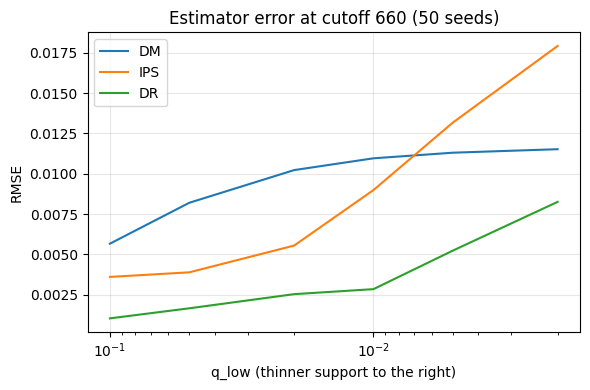

In [32]:
r = t[t['cutoff'] == 660].pivot(index='q-low', columns='estimator', values='rmse')
plt.figure(figsize=(6, 4))
for est in ['DM', 'IPS', 'DR']:
    plt.plot(r.index, r[est], label=est)
plt.xscale('log'); plt.gca().invert_xaxis()
plt.xlabel('q_low (thinner support to the right)'); plt.ylabel('RMSE')
plt.title('Estimator error at cutoff 660 (50 seeds)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.show()